Getting the data

In [6]:
import pandas as pd
df=pd.read_csv("https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv")

In [7]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


In [5]:
df.isna().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [9]:
# Replace nulls in categorical (object/string) columns with 'NA'
cat_cols = df.select_dtypes(include=['object', 'category']).columns
df[cat_cols] = df[cat_cols].fillna('NA')

# Replace nulls in numerical columns with 0.0
num_cols = df.select_dtypes(include=['number']).columns
df[num_cols] = df[num_cols].fillna(0.0)


/tmp/ipykernel_306984/4105438952.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object', 'category']).columns


In [10]:
df.isna().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

Data Preparation

In [12]:
from sklearn.model_selection import train_test_split
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

Question 1: ROC AUC feature importance

In [14]:
from sklearn.metrics import roc_auc_score
for col in [
    "lead_score",
    "number_of_courses_viewed",
    "interaction_count",
    "annual_income"
]:
    auc = roc_auc_score(df_train["converted"], df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(df_train["converted"], -df_train[col])
    print(col, round(auc, 3))

lead_score 0.788
number_of_courses_viewed 0.723
interaction_count 0.765
annual_income 0.608


Question 2: Training the model

In [ ]:
import numpy as np
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

# Separate features and target
y_train = df_train['converted']
y_val = df_val['converted']

X_train_dict = df_train.drop(columns='converted').to_dict(orient='records')
X_val_dict = df_val.drop(columns='converted').to_dict(orient='records')

# One-hot encoding
dv = DictVectorizer(sparse=True)
X_train = dv.fit_transform(X_train_dict).tocsr()
X_val = dv.transform(X_val_dict).tocsr()

# Fix sparse index types for liblinear
for X in (X_train, X_val):
    X.indices = X.indices.astype(np.int32)
    X.indptr = X.indptr.astype(np.int32)

# Train logistic regression
model = LogisticRegression(
    solver='liblinear',
    C=1.0,
    max_iter=1000
)
model.fit(X_train, y_train)

# Predict probabilities and calculate validation AUC
y_pred = model.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred)

print(f'Validation AUC: {auc:.3f}')

Validation AUC: 0.732


Question 3: Precision and Recall

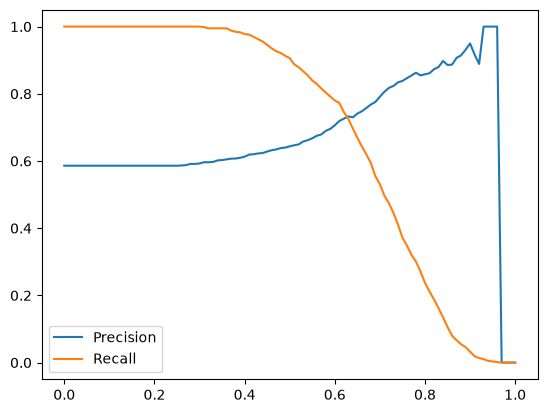

Intersection threshold: 0.63


In [26]:
from sklearn.metrics import precision_score, recall_score
import matplotlib.pyplot as plt

thresholds = np.arange(0.0, 1.01, 0.01)

precisions = []
recalls = []

for t in thresholds:
    y_pred_binary = (y_pred >= t).astype(int)

    precisions.append(precision_score(y_val, y_pred_binary, zero_division=0))
    recalls.append(recall_score(y_val, y_pred_binary, zero_division=0))

plt.plot(thresholds, precisions, label='Precision')
plt.plot(thresholds, recalls, label='Recall')
plt.legend()
plt.show()

differences = np.abs(np.array(precisions) - np.array(recalls))
differences[(np.array(precisions) == 0) & (np.array(recalls) == 0)] = np.inf

print("Intersection threshold:", thresholds[np.argmin(differences)])

Question 4: F1 score

In [35]:
from sklearn.metrics import f1_score

thresholds = np.arange(0.0, 1.01, 0.01)
scores = []

for t in thresholds:
    y_pred_binary = (y_pred >= t).astype(int)
    score = f1_score(y_val, y_pred_binary, zero_division=0)
    scores.append(score)
    print(f"Threshold: {t:.2f}, F1: {score:.3f}")

best_threshold = thresholds[np.argmax(scores)]

print("Best threshold:", best_threshold)
print("Max F1:", max(scores))

Threshold: 0.00, F1: 0.739
Threshold: 0.01, F1: 0.739
Threshold: 0.02, F1: 0.739
Threshold: 0.03, F1: 0.739
Threshold: 0.04, F1: 0.739
Threshold: 0.05, F1: 0.739
Threshold: 0.06, F1: 0.739
Threshold: 0.07, F1: 0.739
Threshold: 0.08, F1: 0.739
Threshold: 0.09, F1: 0.739
Threshold: 0.10, F1: 0.739
Threshold: 0.11, F1: 0.739
Threshold: 0.12, F1: 0.739
Threshold: 0.13, F1: 0.739
Threshold: 0.14, F1: 0.739
Threshold: 0.15, F1: 0.739
Threshold: 0.16, F1: 0.739
Threshold: 0.17, F1: 0.739
Threshold: 0.18, F1: 0.739
Threshold: 0.19, F1: 0.739
Threshold: 0.20, F1: 0.739
Threshold: 0.21, F1: 0.739
Threshold: 0.22, F1: 0.739
Threshold: 0.23, F1: 0.739
Threshold: 0.24, F1: 0.739
Threshold: 0.25, F1: 0.739
Threshold: 0.26, F1: 0.739
Threshold: 0.27, F1: 0.740
Threshold: 0.28, F1: 0.743
Threshold: 0.29, F1: 0.743
Threshold: 0.30, F1: 0.744
Threshold: 0.31, F1: 0.747
Threshold: 0.32, F1: 0.746
Threshold: 0.33, F1: 0.746
Threshold: 0.34, F1: 0.750
Threshold: 0.35, F1: 0.751
Threshold: 0.36, F1: 0.752
T

Question 5: 5-Fold CV

In [39]:
from sklearn.model_selection import KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    train = df_full_train.iloc[train_idx]
    val = df_full_train.iloc[val_idx]

    dv = DictVectorizer()

    X_train = dv.fit_transform(
        train.drop(columns='converted').to_dict(orient='records')
    ).tocsr()

    X_val = dv.transform(
        val.drop(columns='converted').to_dict(orient='records')
    ).tocsr()

    # Fix sparse matrix indices
    for X in (X_train, X_val):
        X.indices = X.indices.astype('int32')
        X.indptr = X.indptr.astype('int32')

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train, train['converted'])

    y_pred = model.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(val['converted'], y_pred)
    scores.append(auc)

    print(f'Fold AUC: {auc:.3f}')

print('Standard deviation:', round(np.std(scores), 3))

Fold AUC: 0.731
Fold AUC: 0.730
Fold AUC: 0.736
Fold AUC: 0.741
Fold AUC: 0.721
Standard deviation: 0.007


Question 6: Hyperparameter Tuning

In [41]:
for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        train = df_full_train.iloc[train_idx]
        val = df_full_train.iloc[val_idx]

        dv = DictVectorizer()
        X_train = dv.fit_transform(
            train.drop(columns='converted').to_dict(orient='records')
        ).tocsr()
        X_val = dv.transform(
            val.drop(columns='converted').to_dict(orient='records')
        ).tocsr()

        for X in (X_train, X_val):
            X.indices = X.indices.astype('int32')
            X.indptr = X.indptr.astype('int32')

        model = LogisticRegression(
            solver='liblinear', C=C, max_iter=1000
        )
        model.fit(X_train, train['converted'])

        y_pred = model.predict_proba(X_val)[:, 1]
        scores.append(roc_auc_score(val['converted'], y_pred))

    print(f'C={C}: mean={np.mean(scores):.3f}, std={np.std(scores):.3f}')

C=1e-06: mean=0.617, std=0.019
C=0.001: mean=0.749, std=0.010
C=1: mean=0.732, std=0.007
